In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directory
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Dataset paths
cleaned_file = BASE_DIR / "data/processed/cleaned_documents.csv"
chunks_file = BASE_DIR / "data/chunks/document_chunks.csv"

# Load datasets
documents = pd.read_csv(cleaned_file)
chunks = pd.read_csv(chunks_file)

print("CampusAssist Module 3 - Exploratory Data Analysis")
print("=" * 50)
print("Documents:", len(documents))
print("Chunks:", len(chunks))
print("Notebook setup completed successfully!")

CampusAssist Module 3 - Exploratory Data Analysis
Documents: 12
Chunks: 12
Notebook setup completed successfully!


In [2]:

# Display the first five documents
print("FIRST FIVE DOCUMENTS")
display(documents.head())

# Dataset information
print("\nDATASET INFORMATION")
documents.info()

# Check missing values
print("\nMISSING VALUES")
print(documents.isnull().sum())

# Check duplicate documents
print("\nDUPLICATE DOCUMENTS")
print(documents.duplicated(subset=["content"]).sum())

# Basic statistical summary
print("\nWORD COUNT SUMMARY")
display(documents["word_count"].describe())


FIRST FIVE DOCUMENTS


,document_id,title,category,file_name,source_type,content,word_count
0,DOC001,Introduction to Data Science,course_guides,introduction_to_data_science.txt,synthetic,Course: Introduction to Data Science\n\nThis c...,64
1,DOC002,Introduction to Artificial Intelligence,course_guides,introduction_to_ai.txt,synthetic,Course: Introduction to Artificial Intelligenc...,46
2,DOC003,Database Management Fundamentals,course_guides,database_fundamentals.txt,synthetic,Course: Database Management Fundamentals\n\nTh...,41
3,DOC004,Data Science Assignment Guidelines,assignment_instructions,data_science_assignment.txt,synthetic,Assignment: Data Science Analysis\n\nStudents ...,57
4,DOC005,AI Project Submission Instructions,assignment_instructions,ai_project_submission.txt,synthetic,Assignment: Artificial Intelligence Project\n\...,54



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   document_id  12 non-null     object
 1   title        12 non-null     object
 2   category     12 non-null     object
 3   file_name    12 non-null     object
 4   source_type  12 non-null     object
 5   content      12 non-null     object
 6   word_count   12 non-null     int64 
dtypes: int64(1), object(6)
memory usage: 800.0+ bytes

MISSING VALUES
document_id    0
title          0
category       0
file_name      0
source_type    0
content        0
word_count     0
dtype: int64

DUPLICATE DOCUMENTS
0

WORD COUNT SUMMARY


count    12.000000
mean     49.833333
std       7.068925
min      40.000000
25%      45.250000
50%      49.500000
75%      54.250000
max      64.000000
Name: word_count, dtype: float64

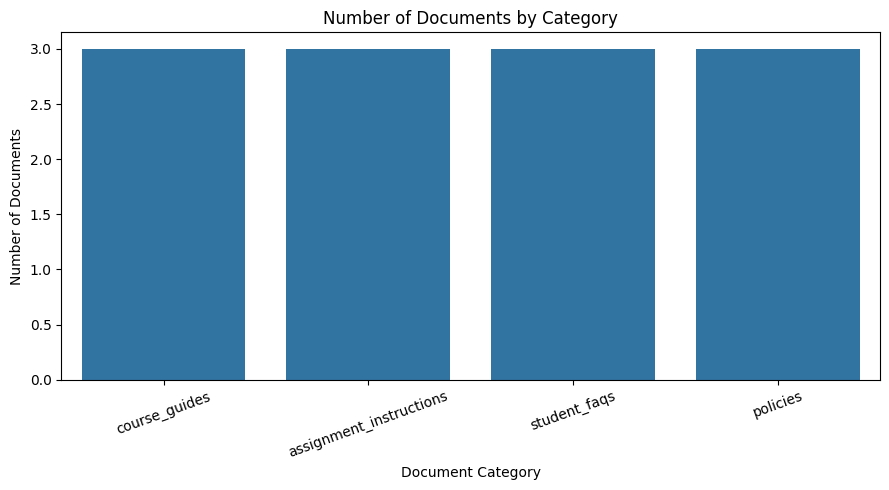

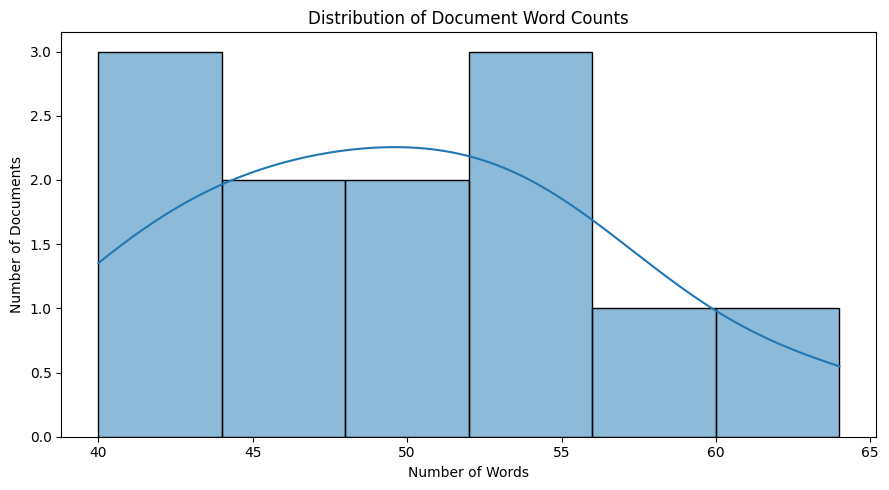

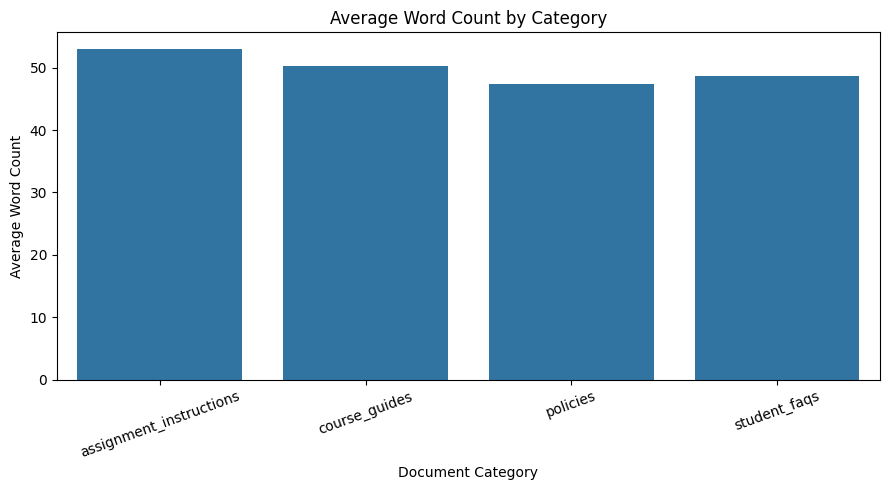

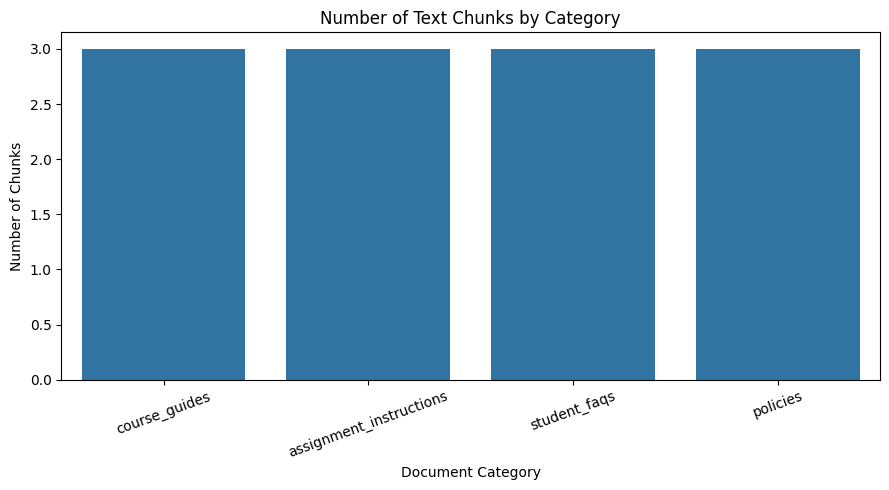

In [3]:

# CampusAssist - Data Visualization

# Chart 1: Number of documents in each category
plt.figure(figsize=(9, 5))
sns.countplot(data=documents, x="category")
plt.title("Number of Documents by Category")
plt.xlabel("Document Category")
plt.ylabel("Number of Documents")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Chart 2: Distribution of document word counts
plt.figure(figsize=(9, 5))
sns.histplot(data=documents, x="word_count", bins=6, kde=True)
plt.title("Distribution of Document Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Documents")
plt.tight_layout()
plt.show()


# Chart 3: Average word count by category
average_words = (
    documents.groupby("category")["word_count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=average_words, x="category", y="word_count")
plt.title("Average Word Count by Category")
plt.xlabel("Document Category")
plt.ylabel("Average Word Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Chart 4: Number of chunks by category
plt.figure(figsize=(9, 5))
sns.countplot(data=chunks, x="category")
plt.title("Number of Text Chunks by Category")
plt.xlabel("Document Category")
plt.ylabel("Number of Chunks")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



# 4. Exploratory Data Analysis - Findings

## 4.1 Document Category Distribution

The dataset contains 12 documents distributed equally across four categories:

- Course Guides: 3 documents
- Assignment Instructions: 3 documents
- Student FAQs: 3 documents
- Policies: 3 documents

This balanced distribution provides an equal number of sample documents for each category.

## 4.2 Document Word Count Distribution

The document word count ranges from 40 to 64 words.

- Average word count: 49.83 words
- Minimum word count: 40 words
- Maximum word count: 64 words

The documents are relatively short and have a similar text length.

## 4.3 Average Word Count by Category

Assignment Instructions have the highest average word count at approximately 53 words.

Policies have the lowest average word count at approximately 48 words.

The difference between category averages is relatively small.

## 4.4 Text Chunk Distribution

The dataset contains 12 text chunks generated from 12 documents.

Each document currently produces one chunk because its content is shorter than the configured chunk size of 100 words.

## 4.5 Key Observations

1. All four categories have equal document representation.
2. No missing values were identified during dataset inspection.
3. No duplicate document content was detected.
4. Document lengths range from 40 to 64 words.
5. Every document currently produces one text chunk.

## 4.6 Limitations

The dataset contains only 12 synthetic documents. Therefore, these findings describe the current prototype dataset and should not be generalized to a real university document collection.

Larger documents and additional categories should be included in future iterations to evaluate chunking and retrieval behavior more thoroughly.

## 4.7 Conclusion

The exploratory analysis provides an initial understanding of the CampusAssist dataset. The documents are evenly distributed across categories, have relatively consistent word counts, and have been successfully converted into text chunks.
